
[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.
First Five Records:
   Feature 1  Feature 2
0   0.658801  -0.355963
1   1.986302  -0.133490
2  -0.111623   0.455081
3   0.905008   0.266798
4   1.181619  -0.494965

Dataset Shape: (300, 2)

DBSCAN Results:
Number of Clusters: 7
Core Points: 251
Border Points: 39
Noise Points: 10

Cluster Labels:
-1     10
 0     98
 1     20
 2    117
 3      9
 4     15
 5     10
 6     21
Name: count, dtype: int64


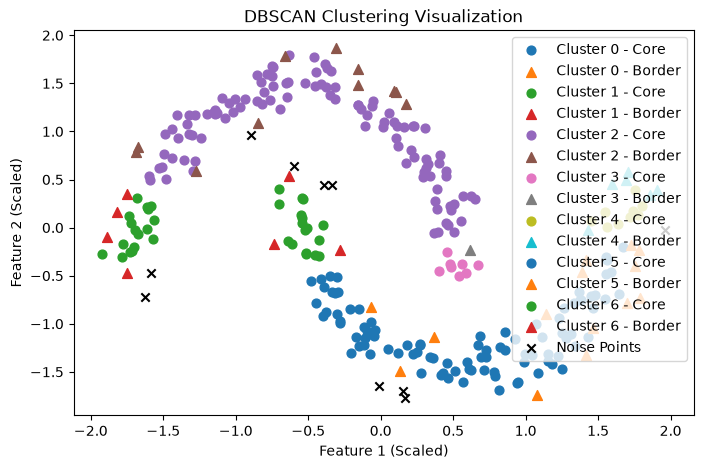


Parameter Tuning Results:
    eps  min_samples  Number of Clusters  Noise Points
0  0.15            5                  18            53
1  0.15           10                   3           269
2  0.20            5                   7            10
3  0.20           10                   7           110
4  0.25            5                   2             2
5  0.25           10                   5            29
6  0.30            5                   2             0
7  0.30           10                   2             2

DBSCAN vs K-Means Comparison:
DBSCAN Clusters: 7
DBSCAN Noise Points: 10
K-Means Clusters: 2
K-Means Noise Points: 0
DBSCAN Silhouette Score: 0.2187
K-Means Silhouette Score: 0.4936


In [2]:

%pip install numpy pandas matplotlib seaborn scikit-learn

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import make_moons
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN, KMeans
from sklearn.metrics import silhouette_score

# Step 1: Generate the Two-Moons dataset
X, y = make_moons(n_samples=300, noise=0.08, random_state=42)

# Do not use the actual labels
X = pd.DataFrame(X, columns=["Feature 1", "Feature 2"])

print("First Five Records:")
print(X.head())

print("\nDataset Shape:", X.shape)

# Step 2: Scale the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Step 3: Apply DBSCAN
eps_value = 0.2
min_samples_value = 5

dbscan = DBSCAN(eps=eps_value, min_samples=min_samples_value)

labels = dbscan.fit_predict(X_scaled)

# Step 4: Identify core, border and noise points
core_mask = np.zeros(len(X_scaled), dtype=bool)
core_mask[dbscan.core_sample_indices_] = True

noise_mask = labels == -1
border_mask = (~core_mask) & (~noise_mask)

print("\nDBSCAN Results:")
print("Number of Clusters:", len(set(labels)) - (1 if -1 in labels else 0))
print("Core Points:", np.sum(core_mask))
print("Border Points:", np.sum(border_mask))
print("Noise Points:", np.sum(noise_mask))

print("\nCluster Labels:")
print(pd.Series(labels).value_counts().sort_index())

# Step 5: Visualize clusters and noise points
plt.figure(figsize=(8, 5))

for cluster in sorted(set(labels)):
    if cluster == -1:
        continue

    cluster_mask = labels == cluster

    plt.scatter(
        X_scaled[cluster_mask & core_mask, 0],
        X_scaled[cluster_mask & core_mask, 1],
        label=f"Cluster {cluster} - Core",
        s=40
    )

    plt.scatter(
        X_scaled[cluster_mask & border_mask, 0],
        X_scaled[cluster_mask & border_mask, 1],
        label=f"Cluster {cluster} - Border",
        marker="^",
        s=50
    )

plt.scatter(
    X_scaled[noise_mask, 0],
    X_scaled[noise_mask, 1],
    color="black",
    marker="x",
    label="Noise Points"
)

plt.title("DBSCAN Clustering Visualization")
plt.xlabel("Feature 1 (Scaled)")
plt.ylabel("Feature 2 (Scaled)")
plt.legend()
plt.show()

# Step 6: Tune eps and min_samples
print("\nParameter Tuning Results:")

tuning_results = []

for eps in [0.15, 0.20, 0.25, 0.30]:
    for min_samples in [5, 10]:

        model = DBSCAN(eps=eps, min_samples=min_samples)
        new_labels = model.fit_predict(X_scaled)

        clusters = len(set(new_labels)) - (1 if -1 in new_labels else 0)
        noise = np.sum(new_labels == -1)

        tuning_results.append([
            eps, min_samples, clusters, noise
        ])

tuning_df = pd.DataFrame(
    tuning_results,
    columns=["eps", "min_samples", "Number of Clusters", "Noise Points"]
)

print(tuning_df)

# Step 7: Compare DBSCAN with K-Means
kmeans = KMeans(n_clusters=2, random_state=42, n_init=10)
kmeans_labels = kmeans.fit_predict(X_scaled)

print("\nDBSCAN vs K-Means Comparison:")

print("DBSCAN Clusters:",
      len(set(labels)) - (1 if -1 in labels else 0))

print("DBSCAN Noise Points:", np.sum(labels == -1))

print("K-Means Clusters:", len(set(kmeans_labels)))
print("K-Means Noise Points: 0")

# Compare Silhouette Scores
dbscan_valid = labels != -1

if len(set(labels[dbscan_valid])) > 1:
    dbscan_score = silhouette_score(
        X_scaled[dbscan_valid],
        labels[dbscan_valid]
    )
    print("DBSCAN Silhouette Score:", round(dbscan_score, 4))

kmeans_score = silhouette_score(X_scaled, kmeans_labels)

print("K-Means Silhouette Score:", round(kmeans_score, 4))
